# A differentiable Z' search on CMS Open Data NanoAOD

**Hackathon notebook, part 2.** In part 1 you optimised a selection by gradient ascent on a flat table someone had prepared for you. Now we should do what a real analyst does: start from CMS Open Data NanoAOD files, build the flat table ourselves, and make the whole chain: object selection, event selection, a neural network, the histogram, into one differentiable program.

**What is different compared to part 1**
- The input is real **NanoAOD**: jagged, per-object arrays that we process with `uproot` and `awkward`.
- The full set of hard→soft transformations, including the difficult case: cuts that **count objects** above a tunable threshold.
- A **neural network** built in JAX, pretrained as a classifier, then fine-tuned *inside* the analysis against the physics objective.
- One **systematic uncertainty** (jet energy scale), propagated through the differentiable chain.

**The search.** Same physics as part 1, now with the real inputs:

| | |
|---|---|
| signal | Z' → $t\bar t$, $m \approx 2$ TeV |
| channel | single muon (lepton+jets) |
| data | 2016 CMS Open Data, $L = 16.4\ \mathrm{fb}^{-1}$ |
| reference | CMS Run-2 search (arXiv:1810.05905) and the CMS Open Data workshop |

This time the signal carries its **real cross-section**, so keep an eye on how large $Z$ gets.

**Plan**
1. Look inside a NanoAOD file.
2. Good objects and structural event cuts.
3. From jagged events to a flat table (and a jet-energy-scale variation).
4. Datasets and weights.
5. A binned significance.
6. The full hard→soft transformations.
7. Optimise the thresholds.
8. A neural network inside the analysis.
9. The systematic.

## 0. Setup

In [1]:
import glob
import time

import numpy as np
import matplotlib.pyplot as plt
import awkward as ak
import uproot
import vector
from tqdm.auto import tqdm

import jax
import jax.numpy as jnp

jax.config.update("jax_enable_x64", True)
plt.rcParams.update({"figure.figsize": (6.5, 3.8), "axes.grid": True, "grid.alpha": 0.3})

/Users/mohamedaly/work/repos/hsf-india-diffprog-hackathon/.pixi/envs/default/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Look inside a NanoAOD file

NanoAOD is CMS's compact event format: one ROOT `Events` tree, one entry per collision event.

- Scalar branches hold one number per event (`PuppiMET_pt`, `genWeight`).
- Object branches hold one number **per object**. Events have different numbers of muons and jets, so these arrays are **jagged**.

The folder `data/nanoaod/` holds skims of the full datasets: the branches below survived, and events were required to fire the single-muon trigger and have MET > 50 GeV. One directory per sample: `signal`, `ttbar_semilep`, `ttbar_had`, `ttbar_lep`, `wjets` (and `data`, real collisions, which we leave alone today).

**TODO.** Open the first signal file with `uproot`, print how many events it holds, and list the branches with their types (`.show()`).

In [2]:
fname = sorted(glob.glob("../data/nanoaod/signal/*.root"))[0]
tree = uproot.open(fname)["Events"]
print(f"{tree.num_entries} events in {fname}")
tree.show(name_width=28)

346 events in ../data/nanoaod/signal/288B512F-09A1-5D48-8D1B-6216C5904FB5.root
name                         | typename                 | interpretation                
-----------------------------+--------------------------+-------------------------------
nMuon_pt                     | int32_t                  | AsDtype('>i4')
Muon_pt                      | float[]                  | AsJagged(AsDtype('>f4'))
nMuon_eta                    | int32_t                  | AsDtype('>i4')
Muon_eta                     | float[]                  | AsJagged(AsDtype('>f4'))
nMuon_phi                    | int32_t                  | AsDtype('>i4')
Muon_phi                     | float[]                  | AsJagged(AsDtype('>f4'))
nMuon_mass                   | int32_t                  | AsDtype('>i4')
Muon_mass                    | float[]                  | AsJagged(AsDtype('>f4'))
nMuon_miniIsoId              | int32_t                  | AsDtype('>i4')
Muon_miniIsoId               | uint8_t[]      

**TODO.** Read the jet transverse momenta of the first five events (`.array(entry_stop=5)`) and print them as lists. 

In [3]:
print(tree["Jet_pt"].array(entry_stop=5).tolist())

[[739.5, 389.0, 109.1875, 84.0625, 52.8125, 30.0625, 25.90625, 18.875, 15.2421875], [635.0, 235.75, 178.75, 164.125, 42.25, 28.46875, 16.65625], [264.75, 150.75, 150.0, 90.9375, 43.90625, 18.796875, 17.421875, 15.8203125], [520.0, 386.25, 306.5, 33.8125, 28.578125, 24.65625, 18.9375], [372.0, 130.625, 106.5625, 88.25, 61.53125, 16.671875]]


**Question.** Why can this not be a plain rectangular numpy array? What does `awkward` give us that numpy does not?

*Your answer:* Events have different numbers of jets (and muons, and fat jets), so the rows have different lengths, while a numpy array must be rectangular. `awkward` stores these variable-length lists contiguously and still lets us operate on them with vectorised, loop-free expressions.

## 2. Good objects and structural event cuts

An analysis never uses raw objects. We first define **good objects**, as jagged boolean masks:

| object | requirements |
|---|---|
| good muon | $p_T > 55$ GeV, $\lvert\eta\rvert < 2.4$, `tightId`, `miniIsoId > 1` |
| good jet (AK4) | $p_T > 30$ GeV, `jetId >= 4` (no b-tag requirement) |
| fat jet (AK8) | $p_T > 500$ GeV (no top-tag requirement) |

| term | meaning |
|---|---|
| AK4 / AK8 | jets clustered with the anti-$k_T$ algorithm, radius 0.4 / 0.8; a boosted top fits inside one AK8 ("fat") jet |
| `tightId` | muon quality requirement |
| `miniIsoId > 1` | the muon is isolated (little activity around it), so not from a hadron decay inside a jet |
| `jetId >= 4` | removes jets caused by detector noise |

Then the **structural event cuts** that define our dataset: exactly 1 good muon, at least 2 good jets, at least 1 fat jet.

Why no b-tag or top-tag threshold here? We plan to **optimise** those thresholds, so they must stay soft, inside the differentiable program: baked into the skim, they could never be lowered again. The structural counts stay hard: they decide which events and objects exist at all, and we never tune them. Fixed quality thresholds (like the muon $p_T > 55$ GeV) sit at trigger and calibration boundaries; they are design constants.

**TODO.** Fill in the two functions.

1. `good_object_masks(arr)` returns the three jagged boolean masks described above.
2. `structural_cut(good_mu, good_jet, fat_jet)` returns one boolean per **event**: exactly 1 good muon AND ≥ 2 good jets AND ≥ 1 fat jet. (`ak.sum(mask, axis=1)` counts per event.)

In [4]:
def good_object_masks(arr):
    good_mu = (arr.Muon_pt > 55) & (abs(arr.Muon_eta) < 2.4) & arr.Muon_tightId & (arr.Muon_miniIsoId > 1)
    good_jet = (arr.Jet_pt > 30) & (arr.Jet_jetId >= 4)
    fat_jet = arr.FatJet_pt > 500
    return good_mu, good_jet, fat_jet


def structural_cut(good_mu, good_jet, fat_jet):
    return (ak.sum(good_mu, axis=1) == 1) & (ak.sum(good_jet, axis=1) >= 2) & (ak.sum(fat_jet, axis=1) >= 1)

Check them on the file from section 1. About **46%** of the (already skimmed) signal events should survive, and far fewer of the W+jets events, which rarely have a 500 GeV jet.

In [5]:
batch = tree.arrays()
keep_event = structural_cut(*good_object_masks(batch))
frac = 100 * ak.sum(keep_event) / len(batch)
print(f"signal: {ak.sum(keep_event)} of {len(batch)} skimmed events pass ({frac:.0f} percent)")

signal: 150 of 346 skimmed events pass (43 percent)


## 3. From jagged events to a flat table

JAX wants rectangular arrays, so once the events are chosen we flatten everything into one number (or one fixed-size row) per event. We build the columns one ingredient at a time.

**First ingredient: the mass.** `m_ttbar` is our fit observable: the invariant mass of (muon + leading fat jet + leading jet + MET). The `vector` library does the Lorentz algebra for us: `vector.array({"pt": ..., "eta": ..., "phi": ..., "mass": ...})` builds an array of four-vectors, `+` adds them, and `.mass` is the invariant mass of the sum. The MET enters as a massless vector with $\eta = 0$ (we only know its transverse part).

**TODO.** Fill in `inv_mass`: build one `vector.array` per (pt, eta, phi, mass) tuple, add them up, and return the mass of the sum.

In [6]:
def inv_mass(particles):
    # invariant mass of the four-vector sum of (pt, eta, phi, mass) tuples
    total = None
    for pt, eta, phi, m in particles:
        v = vector.array({"pt": pt, "eta": eta, "phi": phi, "mass": m})
        total = v if total is None else total + v
    return total.mass

**The other columns.** Besides the mass, the processing loop collects per event:

| column | meaning |
|---|---|
| `met` | missing transverse momentum, the neutrino's imprint on the event |
| `lep_ht` | muon $p_T$ + MET, the transverse energy of the leptonic top decay |
| `btag_pad` | b-tag scores of the good jets (`btagDeepB`, close to 1 = likely a b jet), **padded** to length 6 with −1 so the jagged array becomes rectangular |
| `fatjet_score` | top-tag score of the leading fat jet (`particleNet_TvsQCD`, 1 = merged hadronic top, 0 = ordinary quark or gluon jet) |
| `n_jet`, jet and fat-jet masses | inputs for the neural network later |

The padding value −1 sits far below any threshold, so the pad slots never pass a cut.

**The systematic.** The jet energy scale (JES) is only known to a few percent. We propagate it the standard way: recompute `m_ttbar` with all jet and fat-jet momenta scaled by ±3%, giving two extra columns, `m_ttbar_up` and `m_ttbar_dn`.

**Weights.** As in part 1, each MC event carries a weight so that weighted sums are expected event counts:
$$w = \mathrm{genWeight} \times \frac{\sigma \, L}{\sum \mathrm{genWeight}},$$
with the sum running over *all generated events, before any skim*. Cross-sections and generated sums come from the dataset manifest:

| sample | $\sigma$ [pb] | $\sum$ genWeight |
|---|---|---|
| signal (Z' 2 TeV) | 0.01895 | 2.300 × 10⁵ |
| ttbar_semilep | 364.31 | 4.3548 × 10¹⁰ |
| ttbar_had | 380.11 | 3.3609 × 10¹⁰ |
| ttbar_lep | 87.33 | 3.1401 × 10⁹ |
| wjets | 61 526.7 | 9.6974 × 10¹² |

The signal cross-section is the real one this time.

The skeleton of the processing loop below is provided: it streams every file of every sample and collects the flat columns. **TODO:** fill in the marked lines: build the object masks and the event cut with your section-2 functions, apply the event cut to the batch, apply the jet-energy-scale factor to the leading jet and fat jet, compute the three `m_ttbar` columns with `inv_mass`, and compute the event weight. It processes 18 million events; expect about a minute.

In [7]:
LUMI = 16400.0  # 1/pb
MANIFEST = {  # sample: (cross-section [pb], sum of genWeights before skim)
    "signal":        (0.01895,  230_000.0),
    "ttbar_semilep": (364.31,   43_548_252_780.0),
    "ttbar_had":     (380.11,   33_608_820_031.97),
    "ttbar_lep":     (87.33,    3_140_127_367.19),
    "wjets":         (61526.7,  9_697_410_033_920.0),
}
BRANCHES = ["Muon_pt", "Muon_eta", "Muon_phi", "Muon_mass", "Muon_tightId", "Muon_miniIsoId",
            "Jet_pt", "Jet_eta", "Jet_phi", "Jet_mass", "Jet_btagDeepB", "Jet_jetId",
            "FatJet_pt", "FatJet_eta", "FatJet_phi", "FatJet_mass", "FatJet_particleNet_TvsQCD",
            "PuppiMET_pt", "PuppiMET_phi", "genWeight"]
MAX_JETS = 6
JES = {"m_ttbar": 1.0, "m_ttbar_up": 1.03, "m_ttbar_dn": 0.97}


def process_sample(sample):
    xsec, sum_genweights = MANIFEST[sample]
    columns = {k: [] for k in [*JES, "met", "lep_ht", "n_jet", "jet1_mass", "jet2_mass",
                               "fatjet_mass", "fatjet_score", "btag_pad", "w"]}
    files = [f"{f}:Events" for f in sorted(glob.glob(f"../data/nanoaod/{sample}/*.root"))]
    for batch in uproot.iterate(files, BRANCHES, step_size="200 MB"):
        good_muon, good_jet, fat_jet = good_object_masks(batch)
        keep_event = structural_cut(good_muon, good_jet, fat_jet)

        selected = batch[keep_event]
        if len(selected) == 0:
            continue
        muons = selected[["Muon_pt", "Muon_eta", "Muon_phi", "Muon_mass"]][good_muon[keep_event]]
        jets = selected[["Jet_pt", "Jet_eta", "Jet_phi", "Jet_mass", "Jet_btagDeepB"]][good_jet[keep_event]]
        fatjets = selected[["FatJet_pt", "FatJet_eta", "FatJet_phi", "FatJet_mass",
                            "FatJet_particleNet_TvsQCD"]][fat_jet[keep_event]]

        leading = lambda array: ak.to_numpy(ak.firsts(array))
        muon = (leading(muons.Muon_pt), leading(muons.Muon_eta),
                leading(muons.Muon_phi), leading(muons.Muon_mass))
        leading_jet = (leading(jets.Jet_pt), leading(jets.Jet_eta),
                       leading(jets.Jet_phi), leading(jets.Jet_mass))
        leading_fatjet = (leading(fatjets.FatJet_pt), leading(fatjets.FatJet_eta),
                          leading(fatjets.FatJet_phi), leading(fatjets.FatJet_mass))
        met_pt = ak.to_numpy(selected.PuppiMET_pt)
        met = (met_pt, 0.0 * met_pt, ak.to_numpy(selected.PuppiMET_phi), 0.0 * met_pt)

        for column, scale in JES.items():
            # A jet energy scale shift multiplies the jet four-vector by `scale`:
            # pt and mass scale with it, the direction (eta, phi) does not.
            # The tuples are (pt, eta, phi, mass).
            scaled_jet = (leading_jet[0] * scale, leading_jet[1], leading_jet[2], leading_jet[3] * scale)
            scaled_fatjet = (leading_fatjet[0] * scale, leading_fatjet[1], leading_fatjet[2], leading_fatjet[3] * scale)
            columns[column].append(inv_mass([muon, scaled_jet, scaled_fatjet, met]))

        columns["met"].append(met_pt)
        columns["lep_ht"].append(muon[0] + met_pt)
        columns["n_jet"].append(ak.to_numpy(ak.num(jets.Jet_pt)))
        columns["jet1_mass"].append(leading_jet[3])
        columns["jet2_mass"].append(ak.to_numpy(jets.Jet_mass[:, 1]))
        columns["fatjet_mass"].append(leading_fatjet[3])
        columns["fatjet_score"].append(leading(fatjets.FatJet_particleNet_TvsQCD))
        columns["btag_pad"].append(ak.to_numpy(ak.fill_none(ak.pad_none(jets.Jet_btagDeepB, MAX_JETS, clip=True), -1.0)))
        columns["w"].append(ak.to_numpy(selected.genWeight) * xsec * LUMI / sum_genweights)
    return {k: np.concatenate(v) for k, v in columns.items()}


parts = {}
for sample in tqdm(MANIFEST):
    parts[sample] = process_sample(sample)
    p = parts[sample]
    print(f"{sample:14s}: {len(p['w']):7d} MC events selected, expected yield {p['w'].sum():8.1f}")

  0%|          | 0/5 [00:00<?, ?it/s]

 20%|██        | 1/5 [00:00<00:00,  7.94it/s]

signal        :   18798 MC events selected, expected yield     25.4


 40%|████      | 2/5 [00:19<00:34, 11.51s/it]

ttbar_semilep :  180824 MC events selected, expected yield   7174.2


 60%|██████    | 3/5 [00:23<00:16,  8.10s/it]

... (2 outputs left out)

ttbar_lep     :   67683 MC events selected, expected yield   2174.6


100%|██████████| 5/5 [00:35<00:00,  6.48s/it]

100%|██████████| 5/5 [00:35<00:00,  7.18s/it]

wjets         :     824 MC events selected, expected yield  10237.5


You should see roughly:

| sample | MC events selected | expected yield |
|---|---|---|
| signal | 18 798 | 25.4 |
| ttbar_semilep | 180 824 | 7 174 |
| ttbar_lep | 67 683 | 2 175 |
| ttbar_had | 1 188 | 67 |
| wjets | 824 | 10 237 |

**Question.** `wjets` expects **10 237** events from only **824** simulated ones. What is the weight of a single wjets MC event, and what will that do to any histogram bin it lands in?

*Your answer:* About 12.4 expected events per MC event ($w = \mathrm{genWeight}\,\sigma L / \sum \mathrm{genWeight}$ with the enormous W+jets cross-section). Every histogram bin a wjets event lands in jumps by 12.4 at once, so sparsely populated wjets bins fluctuate strongly; this is what the $b_{\text{floor}}$ term protects the optimiser from.

## 4. Datasets and weights

Exactly as in part 1: stack the scaled features, split the events into a training and a test half, scale the weights up by 2, and keep signal and background weights in separate arrays. The columns we need downstream:

| key | content | units |
|---|---|---|
| `m_ttbar`, `m_ttbar_up`, `m_ttbar_dn` | the three mass variants | TeV |
| `met`, `lep_ht` | the two event scalars | 100 GeV |
| `btag` | padded per-jet b-tag matrix | score, 0 to 1 |
| `top_tag` | leading fat-jet top-tag score | score, 0 to 1 |
| `nn_features` | `[met, lep_ht, max btag, top-tag score, n_jet/10, jet1_mass/100, jet2_mass/100, fatjet_mass/200]` | order 1 |
| `w_s`, `w_b`, `is_sig` | weights and the signal flag | |

**TODO.** Build `events` (the merged columns plus `is_sig`), then `make_dataset(indices)` and the two halves, following the same recipe as part 1 with the new columns.

In [8]:
for name, p in parts.items():
    p["is_sig"] = np.full(len(p["w"]), name == "signal")
events = {k: np.concatenate([parts[s][k] for s in parts]) for k in parts["signal"]}

m_ttbar_tev = events["m_ttbar"] / 1000.0
m_ttbar_up_tev = events["m_ttbar_up"] / 1000.0
m_ttbar_dn_tev = events["m_ttbar_dn"] / 1000.0
met_scaled = events["met"] / 100.0
lep_ht_scaled = events["lep_ht"] / 100.0
X_nn = np.stack([met_scaled, lep_ht_scaled, events["btag_pad"].max(axis=1), events["fatjet_score"],
                 events["n_jet"] / 10.0, events["jet1_mass"] / 100.0, events["jet2_mass"] / 100.0,
                 events["fatjet_mass"] / 200.0], axis=1)

order = np.random.default_rng(0).permutation(len(m_ttbar_tev))
half = len(order) // 2


def make_dataset(indices):
    factor = len(order) / len(indices)
    w = events["w"][indices] * factor
    is_sig = events["is_sig"][indices]
    return {
        "m_ttbar": jnp.array(m_ttbar_tev[indices]), "m_ttbar_up": jnp.array(m_ttbar_up_tev[indices]), "m_ttbar_dn": jnp.array(m_ttbar_dn_tev[indices]),
        "met": jnp.array(met_scaled[indices]), "lep_ht": jnp.array(lep_ht_scaled[indices]),
        "btag": jnp.array(events["btag_pad"][indices]), "top_tag": jnp.array(events["fatjet_score"][indices]),
        "nn_features": jnp.array(X_nn[indices]),
        "w_s": jnp.array(np.where(is_sig, w, 0.0)),
        "w_b": jnp.array(np.where(is_sig, 0.0, w)),
        "is_sig": is_sig,
    }


train = make_dataset(order[:half])
test = make_dataset(order[half:])
print(f"train: {train['nn_features'].shape[0]} MC events, expected yield: {float(train['w_s'].sum()):.1f} signal, {float(train['w_b'].sum()):.0f} background")
print(f"test:  {test['nn_features'].shape[0]} MC events, expected yield: {float(test['w_s'].sum()):.1f} signal, {float(test['w_b'].sum()):.0f} background")

train: 134658 MC events, expected yield: 25.1 signal, 19515 background
test:  134659 MC events, expected yield: 25.7 signal, 19792 background


The expected yields, next to part 1's:

| | signal | background |
|---|---|---|
| part 1 | 1 130 | 4 600 |
| this notebook | **25** | **19 500** |

That is the effect of the real cross-section.

Here is the fit observable, with the backgrounds stacked. This plot is written out for you; every later plot is yours to write.

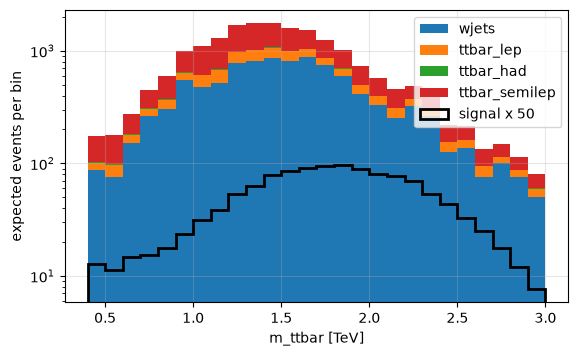

In [9]:
bins = np.linspace(0.4, 3.0, 27)
fig, ax = plt.subplots()
bkg_m = [parts[s]["m_ttbar"] / 1000.0 for s in ["wjets", "ttbar_lep", "ttbar_had", "ttbar_semilep"]]
bkg_w = [parts[s]["w"] for s in ["wjets", "ttbar_lep", "ttbar_had", "ttbar_semilep"]]
ax.hist(bkg_m, bins=bins, weights=bkg_w, stacked=True,
        label=["wjets", "ttbar_lep", "ttbar_had", "ttbar_semilep"])
ax.hist(parts["signal"]["m_ttbar"] / 1000.0, bins=bins, weights=50 * parts["signal"]["w"],
        histtype="step", lw=2, color="k", label="signal x 50")
ax.set_yscale("log")
ax.set_xlabel("m_ttbar [TeV]")
ax.set_ylabel("expected events per bin")
ax.legend()
plt.show()

## 5. A binned significance

The same measure as at the end of part 1: fixed bin edges on `m_ttbar`, a **bKDE** soft histogram with a tunable bandwidth, and bins combined in quadrature,
$$Z = \sqrt{\sum_i \frac{s_i^2}{b_i + b_{\text{floor}}}}.$$
The floor matters even more here, because single wjets events carry large weights.

**TODO.** Rewrite the three part-1 ingredients for fixed `EDGES`: `bkde(x, weights, bandwidth)` (Gaussian-CDF bin contents), `hist(x, weights)` (the hard histogram), and `Z_bins(s, b)`.

In [10]:
B_FLOOR = 1.0
EDGES = jnp.linspace(0.4, 3.0, 14)   # 13 bins on m_ttbar [TeV]


def bkde(x, weights, bandwidth):
    cdf = jax.scipy.stats.norm.cdf((EDGES[None, :] - x[:, None]) / bandwidth)
    return weights @ (cdf[:, 1:] - cdf[:, :-1])


def hist(x, weights):
    inside = (x[:, None] > EDGES[None, :-1]) & (x[:, None] <= EDGES[None, 1:])
    return weights @ inside.astype(float)


def Z_bins(s, b):
    return jnp.sqrt(jnp.sum(s**2 / (b + B_FLOOR)))


print(f"no selection at all: Z = {float(Z_bins(hist(train['m_ttbar'], train['w_s']), hist(train['m_ttbar'], train['w_b']))):.3f}")

no selection at all: Z = 0.216


$Z \approx 0.21$ with no selection. Write that number down: everything from here on is measured against it.

## 6. The full hard→soft transformations

Part 1 only ever cut on **event scalars**, where the soft version is one sigmoid. A real selection has three kinds of cuts, and each transforms differently:

| cut | kind | differentiable version |
|---|---|---|
| MET > $t$, lep-HT > $t$ | threshold on an event scalar | $\sigma\big((x - t)/w\big)$, as in part 1 |
| ≥ 1 jet with btag > $t$ | **count of objects above a tunable threshold** | see below |
| top-tag score of the fat jet > $t$ | threshold on an object scalar (one object per event) | one sigmoid, like an event scalar |
| exactly 1 muon, ≥ 2 jets, ≥ 1 fat jet | structural count | stays hard, never optimised |

The counting cut is the difficult one. "At least one jet with btag > $t$" involves two non-differentiable steps: the per-jet comparison *and* the count. Soften both:
$$n_{\text{soft}} = \sum_{\text{jets}} \sigma\big(k\,(\text{btag}_j - t)\big), \qquad \text{gate} = \sigma\big(k\,(n_{\text{soft}} - 0.5)\big).$$
Here $k$ is the sigmoid steepness, the inverse of part 1's width $\tau$: the 0→1 transition happens over a band of roughly $\pm 1/k$ around the threshold, so $k = 10$ means about $\pm 0.1$ in btag score. Each jet contributes *partially* to the count, and the gate turns "count ≥ 1" into a smooth step at 0.5. The padded slots (btag = −1) contribute $\approx 0$. $k$ and the sigmoid widths (25 GeV for MET and HT) are fixed design constants.

**TODO.** Write the pair of functions. `theta` is a dict with entries `met_threshold`, `lep_ht_threshold`, `btag_threshold`, `top_tag_threshold` (thresholds, in the scaled units); later it also holds `log_bandwidth` and `nn`, which these two functions ignore.

1. `soft_selection(theta, d)`: the product of the four soft pieces above, one weight per event.
2. `hard_selection(theta, d)`: the same four cuts, hard (for the honest evaluation).

In [11]:
def soft_selection(theta, d):
    s_met = jax.nn.sigmoid((d["met"] - theta["met_threshold"]) / 0.25)
    s_ht = jax.nn.sigmoid((d["lep_ht"] - theta["lep_ht_threshold"]) / 0.25)
    n_soft = jnp.sum(jax.nn.sigmoid(10.0 * (d["btag"] - theta["btag_threshold"])), axis=1)
    s_btag = jax.nn.sigmoid(10.0 * (n_soft - 0.5))
    s_tag = jax.nn.sigmoid(10.0 * (d["top_tag"] - theta["top_tag_threshold"]))
    return s_met * s_ht * s_btag * s_tag


def hard_selection(theta, d):
    return ((d["met"] > theta["met_threshold"]) & (d["lep_ht"] > theta["lep_ht_threshold"])
            & (jnp.sum(d["btag"] > theta["btag_threshold"], axis=1) >= 1)
            & (d["top_tag"] > theta["top_tag_threshold"])).astype(float)

And the two significances: soft for gradients, hard for honest numbers.

**TODO.** `Z_soft(theta, d)` uses `soft_selection` and the bKDE with bandwidth $e^{\theta_{\log bw}}$; `Z_hard(theta, d)` uses `hard_selection` and the hard histogram. Then evaluate both at the **CMS workshop working point**: MET > 50 GeV, lep-HT > 150 GeV, btag > 0.5, top-tag > 0.5.

In [12]:
def Z_soft(theta, d):
    sel = soft_selection(theta, d)
    bandwidth = jnp.exp(theta["log_bandwidth"])
    return Z_bins(bkde(d["m_ttbar"], d["w_s"] * sel, bandwidth), bkde(d["m_ttbar"], d["w_b"] * sel, bandwidth))


def Z_hard(theta, d):
    sel = hard_selection(theta, d)
    return float(Z_bins(hist(d["m_ttbar"], d["w_s"] * sel), hist(d["m_ttbar"], d["w_b"] * sel)))


theta_workshop = {"met_threshold": jnp.array(0.5), "lep_ht_threshold": jnp.array(1.5), "btag_threshold": jnp.array(0.5),
            "top_tag_threshold": jnp.array(0.5), "log_bandwidth": jnp.array(np.log(0.05))}
print(f"workshop point: hard Z = {Z_hard(theta_workshop, train):.3f}, soft Z = {float(Z_soft(theta_workshop, train)):.3f}")

workshop point: hard Z = 0.398, soft Z = 0.391


The expert cuts roughly **double** the no-selection $Z$ (≈ 0.21 → ≈ 0.42). Those thresholds took CMS analysts real work to choose. Let us make the computer do it.

**Question.** Why does the counting gate need the *soft count* inside it? What would go wrong if we wrote $\sigma(k(\max_j \text{btag}_j - t))$ instead? When are the two the same?

*Your answer:* For "at least one jet" the max-version selects the same events, but its gradient flows only through the single highest-btag jet, while the soft count lets *every* jet near the threshold pull on the gradient, and only the soft count generalises to "at least two" or any other multiplicity. With $k$ too large both collapse back to a hard step and the gradient vanishes.

## 7. Optimise the thresholds

New ingredient: the parameters now live in a **dict** (a JAX *pytree*), each with its own learning rate, and each clipped to a fixed range after every step. `jax.grad` differentiates functions of pytrees directly; the gradient has the same dict structure.

**TODO.** Write `ascend(objective, theta, learning_rates, bounds, n_steps)`:

1. build the gradient function of `objective` (jit it);
2. each step, update every entry: `theta[k] += learning_rates[k] * grad[k]`; use `jax.tree_util.tree_map` for entries that are themselves pytrees (the NN weights, later);
3. clip each entry listed in `bounds` to its `(lo, hi)`;
4. record the objective value each step and return `theta, history`.

In [13]:
def ascend(objective, theta, learning_rates, bounds, n_steps):
    grad_f = jax.jit(jax.grad(objective))
    history = [float(objective(theta))]
    for _ in range(n_steps):
        g = grad_f(theta)
        theta = {k: jax.tree_util.tree_map(lambda a, b, lr=learning_rates[k]: a + lr * b, theta[k], g[k])
                 for k in theta}
        for k, (lo, hi) in bounds.items():
            theta[k] = jnp.clip(theta[k], lo, hi)
        history.append(float(objective(theta)))
    return theta, np.array(history)

Start the optimiser from a deliberately **bad** working point, as if we had guessed the thresholds badly: MET > 120 GeV, lep-HT > 250 GeV, btag > 0.9, top-tag > 0.9.

**TODO.** Run `ascend` on `Z_soft` (on the training half!) from that point: 400 steps, learning rates `{met_threshold: 0.3, lep_ht_threshold: 0.3, btag_threshold: 0.1, top_tag_threshold: 0.1, log_bandwidth: 0.1}`, bounds `met_threshold: (0.2, 1.5)`, `lep_ht_threshold: (0.5, 3.0)`, `btag_threshold`/`top_tag_threshold`: `(0.0, 1.0)`, `log_bandwidth`: `(log 0.005, log 0.2)`.

In [14]:
theta_bad = {"met_threshold": jnp.array(1.2), "lep_ht_threshold": jnp.array(2.5), "btag_threshold": jnp.array(0.9),
             "top_tag_threshold": jnp.array(0.9), "log_bandwidth": jnp.array(np.log(0.05))}
LEARNING_RATES = {"met_threshold": 0.3, "lep_ht_threshold": 0.3, "btag_threshold": 0.1, "top_tag_threshold": 0.1, "log_bandwidth": 0.1}
BOUNDS = {"met_threshold": (0.2, 1.5), "lep_ht_threshold": (0.5, 3.0), "btag_threshold": (0.0, 1.0), "top_tag_threshold": (0.0, 1.0),
          "log_bandwidth": (np.log(0.005), np.log(0.2))}

print(f"bad start:  hard Z (train) = {Z_hard(theta_bad, train):.3f}")
theta_cuts, history_cuts = ascend(lambda t: Z_soft(t, train), theta_bad, LEARNING_RATES, BOUNDS, 400)
print(f"optimised:  met > {100 * float(theta_cuts['met_threshold']):.0f} GeV, lep-HT > {100 * float(theta_cuts['lep_ht_threshold']):.0f} GeV, "
      f"btag > {float(theta_cuts['btag_threshold']):.2f}, top-tag > {float(theta_cuts['top_tag_threshold']):.2f}, "
      f"bandwidth {1000 * float(jnp.exp(theta_cuts['log_bandwidth'])):.0f} GeV")
print(f"hard Z: train {Z_hard(theta_cuts, train):.3f}, TEST {Z_hard(theta_cuts, test):.3f}")
print(f"workshop point on TEST for comparison: {Z_hard(theta_workshop, test):.3f}")

bad start:  hard Z (train) = 0.308


optimised:  met > 50 GeV, lep-HT > 217 GeV, btag > 0.27, top-tag > 0.54, bandwidth 42 GeV


hard Z: train 0.408, TEST 0.424
workshop point on TEST for comparison: 0.411


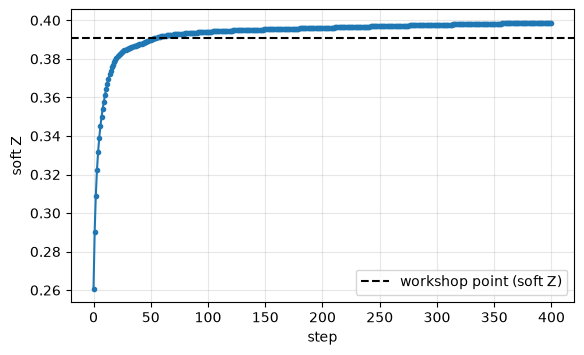

In [15]:
fig, ax = plt.subplots()
ax.plot(history_cuts, ".-")
ax.axhline(float(Z_soft(theta_workshop, train)), color="k", ls="--", label="workshop point (soft Z)")
ax.set_xlabel("step")
ax.set_ylabel("soft Z")
ax.legend()
plt.show()

From a bad guess, gradient ascent recovers, and slightly beats, the published working point in a few seconds. The same behaviour as in part 1, now on real data.

**Questions**: edit this cell with your answers.

- The optimiser pushes the b-tag threshold well *below* 0.5 and MET towards its lower bound. What is it telling you about what actually limits this search?
- After these cuts, which background remains in the bins around 2 TeV, and why can no cut on our variables remove it?

*Your answers:*

1. The thresholds have little left to give: lowering the b-tag cut and MET costs almost nothing because the m_ttbar binning already separates signal from background; the search is limited by the irreducible background under the peak, not by the cuts.
2. Boosted semileptonic $t\bar t$: the identical final state, with a genuine top-tagged fat jet and genuine b jets. Only $m_{t\bar t}$ distinguishes it from the signal, and that is already the fit observable.

## 8. A neural network inside the analysis

The thresholds have hit their plateau: the surviving background is boosted semileptonic $t\bar t$, which looks like signal in every variable we cut on. A neural network can look at **all eight features at once**. We should build one in JAX, in about fifteen lines, and then do something a fixed classifier cannot: let its weights be analysis parameters.

**TODO.** Build the MLP (layers 8 → 16 → 16 → 1, `tanh` activations, linear output = the logit).

1. `init_mlp(key)`: a list of `{"W", "b"}` dicts; initialise `W` with `jax.random.normal(...) * sqrt(2 / n_in)` and `b` with zeros.
2. `nn_logit(params, X)`: the forward pass.
3. `bce(params, X, y)`: binary cross-entropy on logits, in the numerically stable form $\max(z,0) - zy + \log(1 + e^{-|z|})$.

In [16]:
def init_mlp(key, sizes=(8, 16, 16, 1)):
    params = []
    for n_in, n_out in zip(sizes[:-1], sizes[1:]):
        key, sub = jax.random.split(key)
        params.append({"W": jax.random.normal(sub, (n_in, n_out)) * jnp.sqrt(2.0 / n_in),
                       "b": jnp.zeros(n_out)})
    return params


def nn_logit(params, X):
    h = X
    for layer in params[:-1]:
        h = jnp.tanh(h @ layer["W"] + layer["b"])
    return (h @ params[-1]["W"] + params[-1]["b"])[:, 0]


def bce(params, X, y):
    z = nn_logit(params, X)
    return jnp.mean(jnp.maximum(z, 0) - z * y + jnp.log1p(jnp.exp(-jnp.abs(z))))

**Pretraining.** Standard supervised step, signal vs background on MC events (classes balanced by undersampling the background; the sampling is provided). 

**TODO:** write the training loop: full-batch gradient descent on `bce`, learning rate 0.1, 2000 epochs (`jax.value_and_grad`, and `jax.tree_util.tree_map` for the update).

In [17]:
rng = np.random.default_rng(1)
signal_indices = np.where(train["is_sig"])[0]
background_indices = rng.choice(np.where(~train["is_sig"])[0], len(signal_indices), replace=False)
X_pretrain = train["nn_features"][np.concatenate([signal_indices, background_indices])]
y_pretrain = jnp.array(np.r_[np.ones(len(signal_indices)), np.zeros(len(background_indices))])

loss_and_grad = jax.jit(jax.value_and_grad(bce))
nn_params = init_mlp(jax.random.PRNGKey(42))
for epoch in range(2000):
    loss, g = loss_and_grad(nn_params, X_pretrain, y_pretrain)
    nn_params = jax.tree_util.tree_map(lambda p, gr: p - 0.1 * gr, nn_params, g)
print(f"final BCE: {float(loss):.4f}")
nn_pretrained = nn_params

final BCE: 0.5116


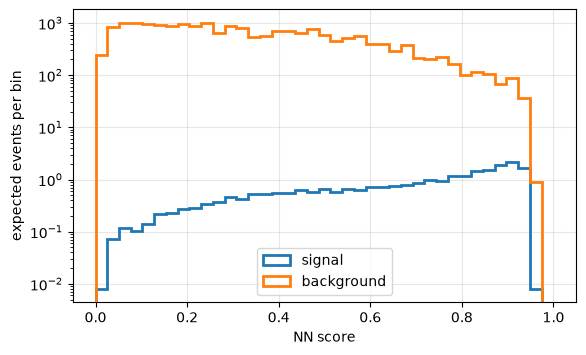

In [18]:
score_test = np.asarray(jax.nn.sigmoid(nn_logit(nn_pretrained, test["nn_features"])))
bins = np.linspace(0, 1, 40)
fig, ax = plt.subplots()
ax.hist(score_test[test["is_sig"]], bins=bins, weights=np.asarray(test["w_s"])[test["is_sig"]],
        histtype="step", lw=2, label="signal")
ax.hist(score_test[~test["is_sig"]], bins=bins, weights=np.asarray(test["w_b"])[~test["is_sig"]],
        histtype="step", lw=2, label="background")
ax.set_yscale("log")
ax.set_xlabel("NN score")
ax.set_ylabel("expected events per bin")
ax.legend()
plt.show()

**The NN as the selection.** Replace all four threshold cuts by a single gate on the score: softly $\sigma\big(10\,(\text{score} - 0.5)\big)$, hard `score > 0.5`. The structural cuts stay, the bKDE stays.

**TODO.** `Z_soft_nn(theta, d)` and `Z_hard_nn(theta, d)` with `theta = {"nn": ..., "log_bandwidth": ...}`. Evaluate the **pretrained** network.

In [19]:
def Z_soft_nn(theta, d):
    score = jax.nn.sigmoid(nn_logit(theta["nn"], d["nn_features"]))
    sel = jax.nn.sigmoid(10.0 * (score - 0.5))
    bandwidth = jnp.exp(theta["log_bandwidth"])
    return Z_bins(bkde(d["m_ttbar"], d["w_s"] * sel, bandwidth), bkde(d["m_ttbar"], d["w_b"] * sel, bandwidth))


def Z_hard_nn(theta, d):
    sel = (jax.nn.sigmoid(nn_logit(theta["nn"], d["nn_features"])) > 0.5).astype(float)
    return float(Z_bins(hist(d["m_ttbar"], d["w_s"] * sel), hist(d["m_ttbar"], d["w_b"] * sel)))


theta_nn = {"nn": nn_pretrained, "log_bandwidth": jnp.array(np.log(0.05))}
print(f"pretrained NN gate: hard Z train {Z_hard_nn(theta_nn, train):.3f}, test {Z_hard_nn(theta_nn, test):.3f}")
print(f"optimised cuts, for comparison:   test {Z_hard(theta_cuts, test):.3f}")

pretrained NN gate: hard Z train 0.312, test 0.302
optimised cuts, for comparison:   test 0.424


The classifier is *good* (check its score plot), and yet the analysis built on it is **worse** than four hand-tunable cuts. Think about that before reading on.

**Question.** The network was trained to separate signal from background events, weighting every event equally. Which events actually matter for $Z$, and why is per-event classification accuracy the wrong objective?

*Your answer:* Only the (weighted) events in the few high-mass bins contribute to $Z$: a handful of signal events against the steeply falling tails. The BCE loss treated every MC event equally, so the network spent its capacity separating the low-mass bulk, where there is no sensitivity at all, and its 0.5 threshold sacrifices the rare high-mass region. Per-event classification accuracy is not the analysis objective.

**Fine-tuning against the physics.** The fix is the whole point of this hackathon: the NN weights are just more analysis parameters, and `Z_soft_nn` is differentiable with respect to them. Your `ascend` already handles pytrees.

**TODO.** Fine-tune `theta_nn` on `Z_soft_nn` (training half): 400 steps, learning rates `{"nn": 2e-3, "log_bandwidth": 0.1}`, bounds only on `log_bandwidth`.

In [20]:
theta_tuned, history_nn = ascend(lambda t: Z_soft_nn(t, train), theta_nn,
                              {"nn": 2e-3, "log_bandwidth": 0.1},
                              {"log_bandwidth": (np.log(0.005), np.log(0.2))}, 400)
print(f"fine-tuned NN:  hard Z train {Z_hard_nn(theta_tuned, train):.3f}, test {Z_hard_nn(theta_tuned, test):.3f}")
print(f"(pretrained was test {Z_hard_nn(theta_nn, test):.3f}; optimised cuts test {Z_hard(theta_cuts, test):.3f})")


fine-tuned NN:  hard Z train 0.441, TEST 0.444
(pretrained was test 0.302; optimised cuts test 0.424)


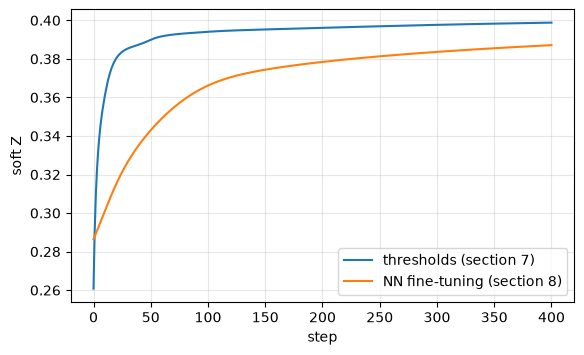

In [21]:
fig, ax = plt.subplots()
ax.plot(history_cuts, label="thresholds (section 7)")
ax.plot(history_nn, label="NN fine-tuning (section 8)")
ax.set_xlabel("step")
ax.set_ylabel("soft Z")
ax.legend()
plt.show()

The same network, with the same architecture and the same inputs, goes from *worse than cuts* to *better than cuts*, not by training longer but by training **on the right objective**. The classifier became an analysis.

**Things to try**: the two cells below are yours.

In [22]:
theta_rand = {"nn": init_mlp(jax.random.PRNGKey(7)), "log_bandwidth": jnp.array(np.log(0.05))}
theta_rand, _ = ascend(lambda t: Z_soft_nn(t, train), theta_rand,
                       {"nn": 2e-3, "log_bandwidth": 0.1}, {"log_bandwidth": (np.log(0.005), np.log(0.2))}, 400)
print(f"random init, fine-tuned: hard Z test {Z_hard_nn(theta_rand, test):.3f}")
print(f"pretrained + fine-tuned: hard Z test {Z_hard_nn(theta_tuned, test):.3f}")

random init, fine-tuned: hard Z test 0.212
pretrained + fine-tuned: hard Z test 0.444


In [23]:
def Z_soft_all(theta, d):
    score = jax.nn.sigmoid(nn_logit(theta["nn"], d["nn_features"]))
    sel = soft_selection(theta, d) * jax.nn.sigmoid(10.0 * (score - 0.5))
    bandwidth = jnp.exp(theta["log_bandwidth"])
    return Z_bins(bkde(d["m_ttbar"], d["w_s"] * sel, bandwidth), bkde(d["m_ttbar"], d["w_b"] * sel, bandwidth))


def Z_hard_all(theta, d):
    score = jax.nn.sigmoid(nn_logit(theta["nn"], d["nn_features"]))
    sel = hard_selection(theta, d) * (score > 0.5)
    return float(Z_bins(hist(d["m_ttbar"], d["w_s"] * sel), hist(d["m_ttbar"], d["w_b"] * sel)))


theta_all = {k: theta_cuts[k] for k in ["met_threshold", "lep_ht_threshold", "btag_threshold", "top_tag_threshold", "log_bandwidth"]}
theta_all["nn"] = nn_pretrained
theta_all, _ = ascend(lambda t: Z_soft_all(t, train), theta_all, {**LEARNING_RATES, "nn": 2e-3}, BOUNDS, 400)
print(f"thresholds + NN together: hard Z test {Z_hard_all(theta_all, test):.3f}")

thresholds + NN together: hard Z test 0.455


## 9. The systematic

$Z = s/\sqrt{b}$ pretends we know the background perfectly. We propagated a ±3% jet-energy-scale shift into `m_ttbar_up` / `m_ttbar_dn`; the standard recipe turns that into per-bin uncertainties and (as in part 1's stretch goal)
$$Z_{\text{sys}} = \sqrt{\sum_i \frac{s_i^2}{b_i + (\delta b_i)^2 + b_{\text{floor}}}}, \qquad \delta b_i = \max\big(|b_i^{\text{up}} - b_i|, |b_i^{\text{dn}} - b_i|\big).$$

**TODO.** `Z_hard_nn_sys(theta, d)`: same as `Z_hard_nn` but with the penalty, using the `m_ttbar_up` / `m_ttbar_dn` columns for the background. Evaluate the fine-tuned analysis on the test half.

In [24]:
def Z_hard_nn_sys(theta, d):
    sel = (jax.nn.sigmoid(nn_logit(theta["nn"], d["nn_features"])) > 0.5).astype(float)
    s = hist(d["m_ttbar"], d["w_s"] * sel)
    b = hist(d["m_ttbar"], d["w_b"] * sel)
    b_up = hist(d["m_ttbar_up"], d["w_b"] * sel)
    b_dn = hist(d["m_ttbar_dn"], d["w_b"] * sel)
    db = jnp.maximum(jnp.abs(b_up - b), jnp.abs(b_dn - b))
    return float(jnp.sqrt(jnp.sum(s**2 / (b + db**2 + B_FLOOR))))


print(f"fine-tuned NN on TEST:  Z = {Z_hard_nn(theta_tuned, test):.3f},  with JES systematic: {Z_hard_nn_sys(theta_tuned, test):.3f}")

fine-tuned NN on TEST:  Z = 0.444,  with JES systematic: 0.331


A ±3% energy scale costs a sizeable fraction of the sensitivity: the background shifts along the steeply falling $m_{t\bar t}$ spectrum, and in the signal bins that shift is comparable to the background's own size.

**Thing to try**: the cell below is yours.

In [25]:
def Z_soft_nn_sys(theta, d):
    score = jax.nn.sigmoid(nn_logit(theta["nn"], d["nn_features"]))
    sel = jax.nn.sigmoid(10.0 * (score - 0.5))
    bandwidth = jnp.exp(theta["log_bandwidth"])
    s = bkde(d["m_ttbar"], d["w_s"] * sel, bandwidth)
    b = bkde(d["m_ttbar"], d["w_b"] * sel, bandwidth)
    db = jnp.maximum(jnp.abs(bkde(d["m_ttbar_up"], d["w_b"] * sel, bandwidth) - b),
                     jnp.abs(bkde(d["m_ttbar_dn"], d["w_b"] * sel, bandwidth) - b))
    return jnp.sqrt(jnp.sum(s**2 / (b + db**2 + B_FLOOR)))


theta_sys, _ = ascend(lambda t: Z_soft_nn_sys(t, train), theta_nn,
                      {"nn": 2e-3, "log_bandwidth": 0.1}, {"log_bandwidth": (np.log(0.005), np.log(0.2))}, 400)
print(f"tuned on Z:     test Z = {Z_hard_nn(theta_tuned, test):.3f},  Z_sys = {Z_hard_nn_sys(theta_tuned, test):.3f}")
print(f"tuned on Z_sys: test Z = {Z_hard_nn(theta_sys, test):.3f},  Z_sys = {Z_hard_nn_sys(theta_sys, test):.3f}")

tuned on Z:     test Z = 0.444,  Z_sys = 0.331
tuned on Z_sys: test Z = 0.462,  Z_sys = 0.417
